In [121]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [113]:
utf = 'utf8'
orders = pd.read_csv('../data/raw/olist_orders_dataset.csv', encoding=utf)
order_items = pd.read_csv('../data/raw/olist_order_items_dataset.csv', encoding=utf)
df_sellers = pd.read_csv('../data/raw/olist_sellers_dataset.csv', encoding=utf)
df_order_reviews = pd.read_csv('../data/raw/olist_order_reviews_dataset.csv', encoding=utf)
df_geolocation = pd.read_csv('../data/raw/olist_geolocation_dataset.csv', encoding=utf)
order_customer = pd.read_csv('../data/raw/olist_customers_dataset.csv', encoding=utf)
products = pd.read_csv('../data/raw/olist_products_dataset.csv', encoding=utf)
payments = pd.read_csv('../data/raw/olist_order_payments_dataset.csv', encoding=utf)

In [114]:
order_customer.columns

customers_by_city = order_customer[
    ['customer_id', 'customer_city', 'customer_state']
]


# order_customer['customer_id'].is_unique


# print(len(order_customer['customer_id']))
# print(len(order_customer['customer_unique_id']))
# customer_counts = order_customer.groupby("customer_unique_id")["customer_id"].nunique()
# customer_counts[customer_counts > 1]
# customer_counts.value_counts().sort_index()

In [115]:
# print(df_payments[df_payments.duplicated(subset='order_id', keep=False)])

payments_by_order = payments.groupby('order_id')[['payment_value', 'payment_installments']] \
                                    .agg({'payment_value' : 'sum', 'payment_installments': 'mean'})

payment_methods_by_order = (
    pd.get_dummies(
        payments[['order_id', 'payment_type']],
        columns=['payment_type']
        ).groupby('order_id')
        .max()
        )


orders_with_payment_totals = orders.merge(payments_by_order,
                                    how='left', 
                                    left_on='order_id', 
                                    right_index=True,
                                    validate='one_to_one')

orders_with_payments = orders_with_payment_totals.merge(payment_methods_by_order,
                                                how='left',
                                                left_on='order_id',
                                                right_index=True,
                                                validate="one_to_one"                                                
                                                )


date_cols = ['order_delivered_carrier_date',
             'order_approved_at',
             'order_delivered_customer_date',
             'order_estimated_delivery_date',
             'order_purchase_timestamp']

for col in date_cols:
    orders_with_payments[col] = pd.to_datetime(orders_with_payments[col])


orders_with_customers = orders_with_payments.merge(
                        customers_by_city,
                        how='left',
                        on='customer_id',
                        validate='one_to_one'
)

assert orders_with_customers['order_id'].is_unique
assert len(orders_with_customers) == len(orders_with_payments)

# orders_with_payments[['order_purchase_timestamp','order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']]

# print(orders_with_payments.describe())
# print(orders_with_payments.columns)

# orders_with_payments[['order_id' ,'payment_value', 'payment_installments', *orders_with_payments.filter(like="payment_type_").columns]]

In [7]:
# top_cities = orders_with_customers["customer_city"].value_counts().head(10).index
# orders_with_customers_top_cities = orders_with_customers[
#     orders_with_customers['customer_city'].isin(top_cities)
# ]

# filtered = orders_with_customers_top_cities[
#     orders_with_customers_top_cities['order_purchase_timestamp_year'] == 2017
# ]

# date_cols = ['order_delivered_carrier_date','order_approved_at', 'order_delivered_customer_date', 'order_estimated_delivery_date','order_purchase_timestamp']
# components = ['year', 'month', 'day', 'hour', 'minute', 'second']

# for c in date_cols:
#     for component in components:
#         orders_with_customers[f'{c}_{component}'] = getattr(
#             orders_with_customers[c].dt,
#             component
#         )
            

# orders_with_customers = orders_with_customers.drop(columns=cols)



# plt.figure(figsize=(20,10))
# sns.countplot(data=filtered,
#             x='customer_city',
#             hue='order_purchase_timestamp_month'
#             )
# plt.xticks(rotation=45)
# plt.show()

# pd.crosstab(
#     filtered['order_purchase_timestamp_month'],
#     filtered['order_purchase_timestamp_year']
# )

In [116]:

orders_with_customers.columns.tolist()

# order_items_grouped = order_items.groupby('order_id')[['product_id', 'order_item_id', 'seller_id', 'price']].agg(
#     {'price' : 'sum'}
# )



# order_items_products = products.merge(
#     order_items,
#     how='outer',
#     on='product_id',
# )

# products.head()



['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'payment_value',
 'payment_installments',
 'payment_type_boleto',
 'payment_type_credit_card',
 'payment_type_debit_card',
 'payment_type_not_defined',
 'payment_type_voucher',
 'customer_city',
 'customer_state']

In [117]:
order_items_products = order_items.merge(
    products,
    how='left',
    on='product_id',
    validate='many_to_one'
)

order_items_products_filtered = order_items_products[[
    'order_id','product_category_name' 
    ]]

order_items_products_encoded = (pd.get_dummies(
        order_items_products_filtered,
        columns=['product_category_name']).groupby('order_id').max())



final_df = orders_with_customers.merge(
    order_items_products_encoded,
    how='left',
    left_on='order_id',
    right_index=True,
    validate='one_to_one'
)

assert final_df['order_id'].is_unique
assert len(final_df) == len(orders_with_customers)

In [131]:
top_cities = final_df["customer_city"].value_counts().head(10).index
model_data = final_df[
    (final_df['customer_city'].isin(top_cities)) & (final_df['order_purchase_timestamp'].dt.year == 2017)
]


print(model_data.head())
print(model_data.shape)
print(model_data["order_id"].is_unique)
print(model_data["customer_city"].nunique())
print(model_data["payment_value"].isna().sum())

                            order_id                       customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date  payment_value  payment_installments payment_type_boleto payment_type_credit_card payment_type_debit_card payment_type_not_defined payment_type_voucher   customer_city customer_state product_category_name_agro_industria_e_comercio product_category_name_alimentos product_category_name_alimentos_bebidas product_category_name_artes product_category_name_artes_e_artesanato product_category_name_artigos_de_festas product_category_name_artigos_de_natal product_category_name_audio product_category_name_automotivo product_category_name_bebes product_category_name_bebidas product_category_name_beleza_saude product_category_name_brinquedos product_category_name_cama_mesa_banho product_category_name_casa_conforto product_category_name_casa_conforto_2  \
0   e481f51cbdc54678b7cc49136

In [ ]:

X = pd.get_dummies(
    model_data['customer_city'],
    drop_first=True,
    dtype=float
)

X['payment_installments'] = (
    model_data['payment_installments'].astype(float)
    )


X = sm.add_constant(X)

Y = model_data['payment_value']




model = sm.OLS(
    endog=Y,
    exog=X
).fit(cov_type='HC3')

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          payment_value   R-squared:                       0.082
Model:                            OLS   Adj. R-squared:                  0.082
Method:                 Least Squares   F-statistic:                     68.89
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          2.43e-138
Time:                        21:11:34   Log-Likelihood:            -1.0428e+05
No. Observations:               15259   AIC:                         2.086e+05
Df Residuals:                   15248   BIC:                         2.087e+05
Df Model:                          10                                         
Covariance Type:                  HC3                                         
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    72.86

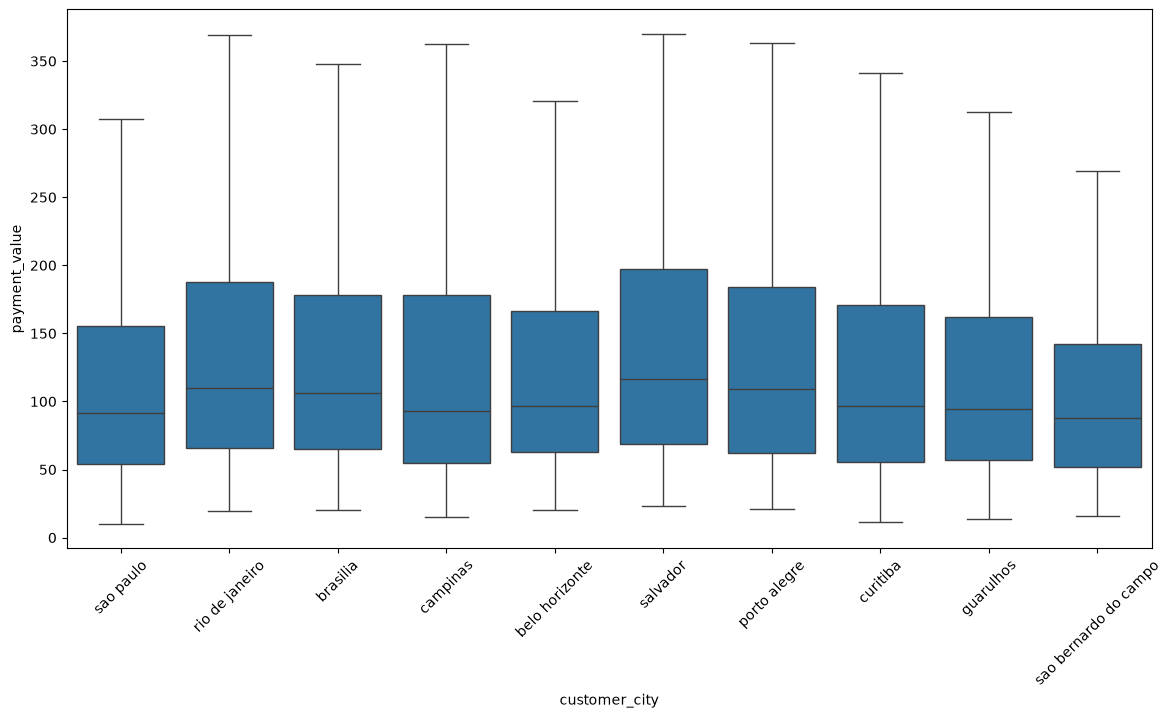

In [120]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=model_data,
    x='customer_city',
    y='payment_value',
    showfliers=False
)

plt.xticks(rotation=45)
plt.show()

In [172]:
model_data["purchase_month"] = (
    model_data["order_purchase_timestamp"].dt.month
)

model_data = model_data.loc[
    model_data["order_status"] == "delivered"
].copy()

# model_data = model_data.drop(columns=['product_category_name_artes_e_artesanato', 
#                                       'product_category_name_fraldas_higiene',
#                                       'product_category_name_portateis_cozinha_e_preparadores_de_alimentos'])
category_cols = model_data.filter(
    like='product_category_name_'
).columns

formula = (
    "payment_value ~ C(customer_city) + C(purchase_month)" + "".join(f' + Q("{col}")' for col in category_cols)
)


model_B = smf.ols(
    formula=formula,
    data=model_data
).fit(cov_type="HC3")

print(model_B.summary())

model_A = smf.ols(
    formula="payment_value ~ C(customer_city)",
    data=model_data
).fit(cov_type="HC3")


                            OLS Regression Results                            
Dep. Variable:          payment_value   R-squared:                       0.116
Model:                            OLS   Adj. R-squared:                  0.110
Method:                 Least Squares   F-statistic:                     13.46
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          7.64e-187
Time:                        23:29:54   Log-Likelihood:                -99633.
No. Observations:               14650   AIC:                         1.994e+05
Df Residuals:                   14559   BIC:                         2.001e+05
Df Model:                          90                                         
Covariance Type:                  HC3                                         
                                                                                        coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------

/var/folders/3h/0qfkfvf942j_tby92t874bph0000gn/T/ipykernel_49207/1426480581.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(cov_type="HC3")
/Users/cankale/miniforge3/envs/olist/lib/python3.12/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 93, but rank is 90
  res = self.wald_test(


In [157]:
X_model = model_A.model.exog

print("Columns:", X_model.shape[1])
print("Matrix rank:", np.linalg.matrix_rank(X_model))
print("Rank deficiency:", X_model.shape[1] - np.linalg.matrix_rank(X_model))

Columns: 10
Matrix rank: 10
Rank deficiency: 0


In [158]:
design = pd.DataFrame(
    model_A.model.exog,
    columns=model_A.model.exog_names
)

design.columns[design.nunique() == 1].tolist()

['Intercept']

In [ ]:
print(model_A.nobs, model_B.nobs)
assert model_A.model.data.row_labels.equals(
    model_B.model.data.row_labels
)

14650.0 14650.0


In [160]:
city_cols = model_A.params.index.str.startswith("C(customer_city)")

comparison = pd.DataFrame({
    "Model A": model_A.params[city_cols],
    "Model B": model_B.params[model_A.params.index[city_cols]]
})

display(comparison)

,Model A,Model B
C(customer_city)[T.brasilia],25.937723,14.730556
C(customer_city)[T.campinas],5.538911,1.387097
C(customer_city)[T.curitiba],5.228792,1.436057
C(customer_city)[T.guarulhos],-8.823248,-11.835301
C(customer_city)[T.porto alegre],8.324264,1.993025
C(customer_city)[T.rio de janeiro],24.565672,18.806427
C(customer_city)[T.salvador],31.023401,22.013593
C(customer_city)[T.sao bernardo do campo],-14.060219,-17.643903
C(customer_city)[T.sao paulo],-7.638622,-10.216956


In [232]:
category_cols = [
    col for col in model_data.filter(like="product_category_name_").columns
    if model_data[col].nunique() > 1
]

formula = (
    "payment_value ~ C(customer_city) + C(purchase_month)"
    + "".join(f' + Q("{col}")' for col in category_cols)
)

model_B = smf.ols(
    formula=formula,
    data=model_data
).fit(cov_type="HC3")

model_A_trimmed = smf.ols(
    "payment_value ~ C(customer_city)",
    data=model_data_trimmed
).fit(cov_type="HC3")

In [167]:
model_data["payment_value"].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
)

count    14650.000000
mean       151.963878
std        231.239210
min         10.070000
50%         98.440000
90%        288.265000
95%        418.410500
99%       1009.678300
99.9%     2253.491150
max      13664.080000
Name: payment_value, dtype: float64

In [224]:
threshold = model_data["payment_value"].quantile(0.99)

category_cols_trimmed = [
    col for col in model_data_trimmed.filter(like="product_category_name_").columns
    if model_data_trimmed[col].nunique() > 1
]

formula_trimmed = (
    "payment_value ~ C(customer_city) + C(purchase_month)"
    + "".join(f' + Q("{col}")' for col in category_cols_trimmed)
)

model_data_trimmed = model_data[
    model_data["payment_value"] <= threshold
]

model_B_trimmed = smf.ols(
    formula=formula_trimmed,
    data=model_data_trimmed
).fit(cov_type="HC3")


In [225]:
X = model_B_trimmed.model.exog

print("Columns:", X.shape[1])
print("Rank:", np.linalg.matrix_rank(X))

print(model_B_trimmed.wald_test_terms().table.loc["C(customer_city)"])

Columns: 91
Rank: 91
statistic        8.148555e+01
pvalue           8.187348e-14
df_constraint    9.000000e+00
Name: C(customer_city), dtype: float64


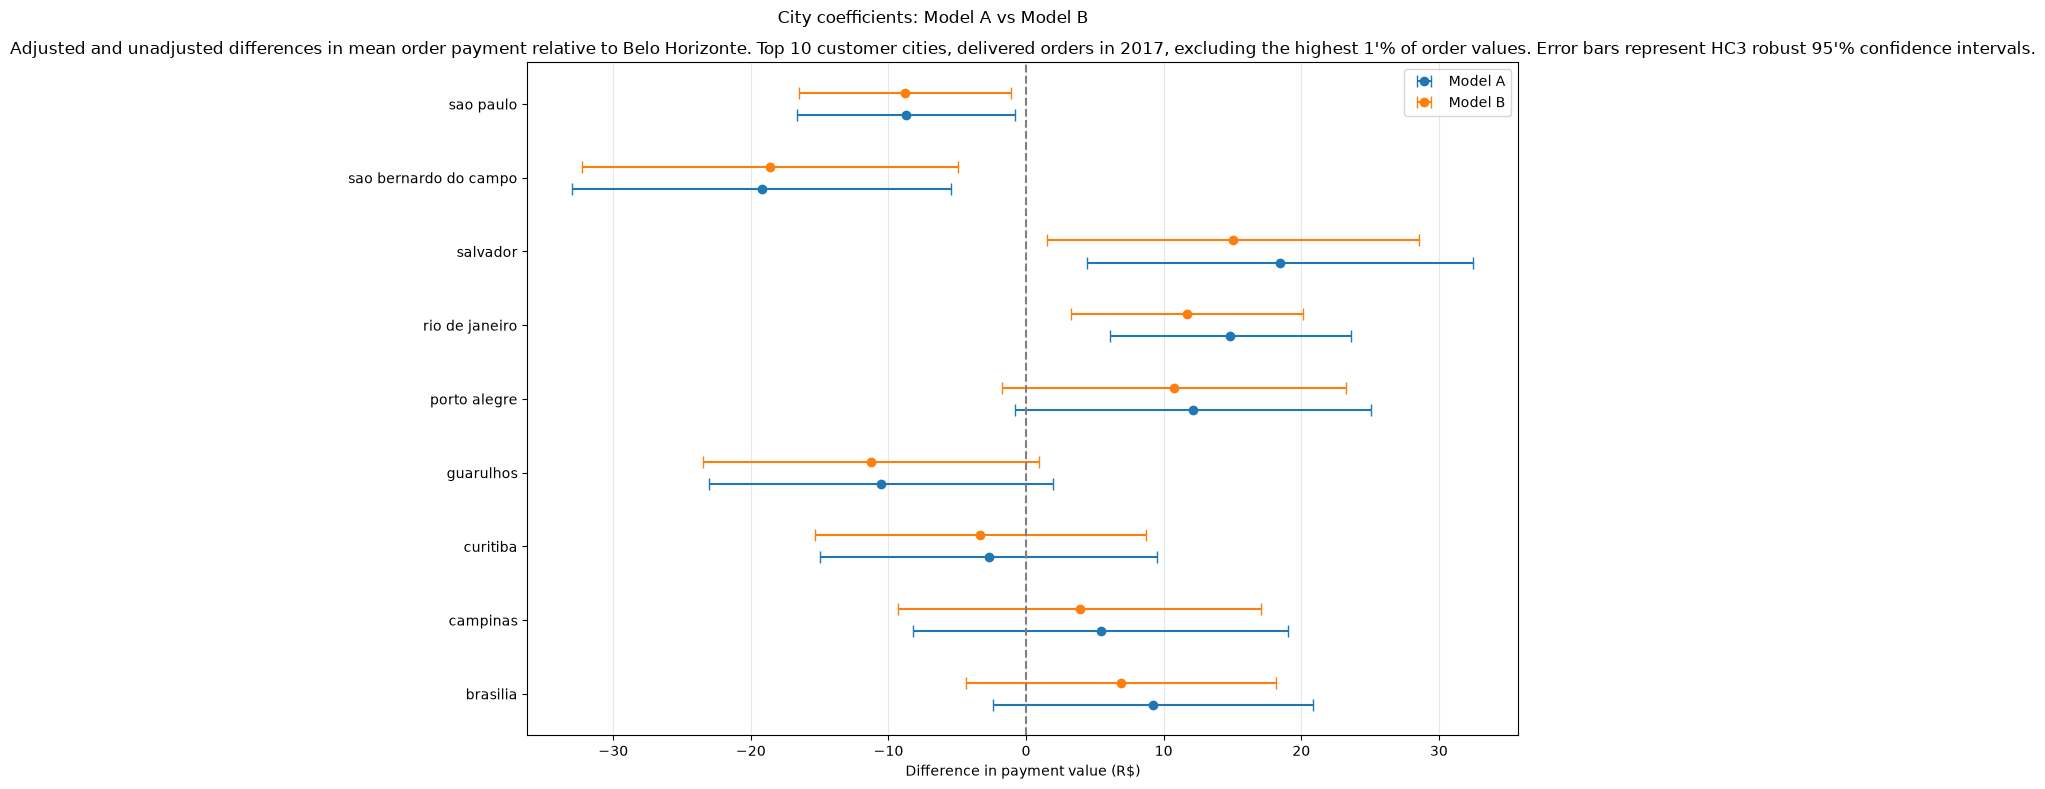

In [ ]:
city_cols = model_B_trimmed.params.index[
    model_B_trimmed.params.index.str.startswith("C(customer_city)")   
]

cities = [c.split("[T.")[1].rstrip("]") for c in city_cols]
y_pos = np.arange(len(cities))

fig, ax = plt.subplots(figsize=(12,8))


for model, label, offset in [
    (model_A_trimmed, "Model A", -0.15),
    (model_B_trimmed, "Model B", 0.15)
]:
    coef = model.params.loc[city_cols]
    ci = model.conf_int().loc[city_cols]

    ax.errorbar(
        coef,
        y_pos + offset,
        xerr=[coef - ci[0], ci[1] - coef],
        fmt="o",
        capsize=4,
        label=label
    )

ax.set_yticks(y_pos, cities)
ax.axvline(0, color='gray', linestyle="--")
ax.set_xlabel("Difference in payment value (R$)")
ax.set_title("Adjusted and unadjusted differences in mean order payment relative to Belo Horizonte.\n" \
"Top 10 customer cities, delivered orders in 2017, excluding the highest 1'% of order values.\n " \
"Error bars represent HC3 robust 95'% confidence intervals.")
ax.legend()
ax.grid(axis='x', alpha=0.3)
plt.suptitle("City coefficients: Model A vs Model B")
plt.tight_layout()
plt.show()